In [128]:
import numpy as np
import matplotlib.pyplot as plt

In [129]:
h = 2**(-4)
epsilon = 0.05

print(epsilon / h)

0.8


In [130]:
def a(X, epsilon=1):
    return (2 + np.cos(2 * np.pi * X/epsilon))**(-1)

def u_epsilon(X, epsilon=1):
    return X - X**2 \
        + epsilon * (1/2 - X) * np.sin(2 * np.pi * X / epsilon) / (2 * np.pi) \
        + epsilon**2 * (1 - np.cos(2 * np.pi * X / epsilon)) / (4 * np.pi **2)

def u_0(X):
    return X - X**2

a0 = 1/2

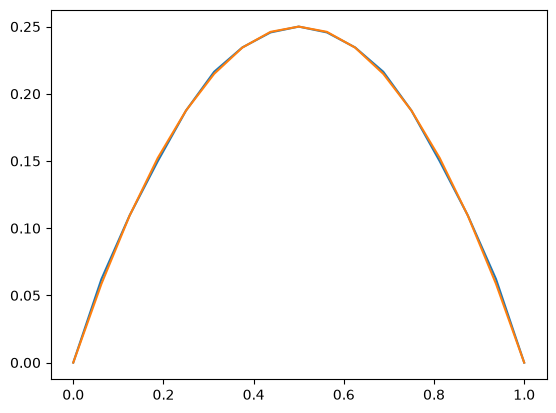

In [131]:
X = np.linspace(0, 1, int(1/h) + 1)

plt.plot(X, u_epsilon(X, epsilon))
plt.plot(X, u_0(X))
plt.show()

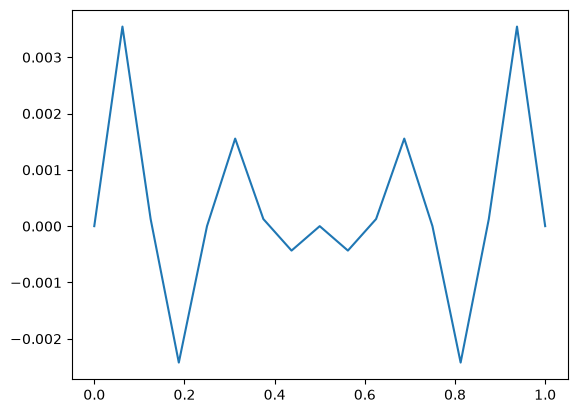

In [132]:
plt.plot(X, u_epsilon(X, epsilon) - u_0(X))
plt.show()

In [133]:
import numpy as np
from scipy.sparse import diags
from scipy.sparse.linalg import spsolve


def u_fem(X, epsilon):
    N = len(X) - 1
    h = X[1] - X[0]

    p = np.array([-1.0, 1.0]) / np.sqrt(3.0)
    mid = 0.5 * (X[:-1] + X[1:])
    xq = mid[:, None] + 0.5 * h * p

    k = np.mean(a(xq, epsilon), axis=1) / h

    main = k[:-1] + k[1:]
    off = -k[1:-1]
    A = diags([off, main, off], [-1, 0, 1]).tocsc()

    b = np.full(N - 1, h)

    u = np.zeros(N + 1)
    u[1:-1] = spsolve(A, b)
    return u

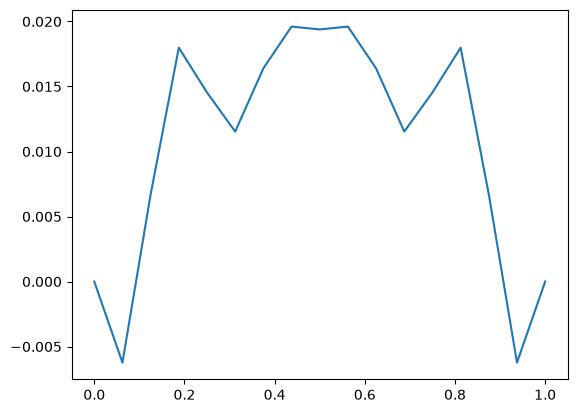

In [134]:
plt.plot(X, u_epsilon(X, epsilon) - u_fem(X, epsilon))
plt.show()

In [135]:
delta = np.linspace(epsilon, 1, 1000)

R = delta / epsilon

def a_R(R, theta=0):
    return (
        2.0
        + np.cos(2.0 * np.pi * theta)
        * np.sin(np.pi * R)
        / (np.pi * R)
    )**(-1)

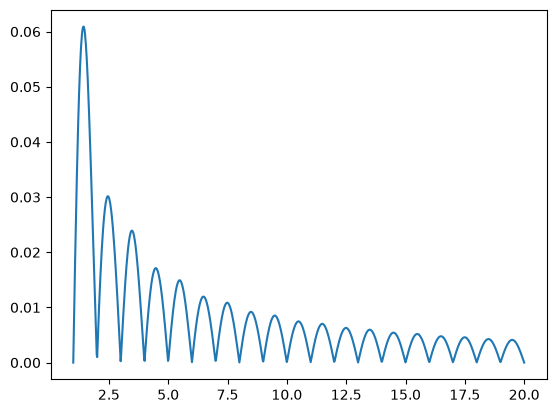

In [136]:
plt.plot(R, np.abs(a_R(R) - a0))
plt.show()